<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_11/lab_work_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Завдання 1: Закон великих чисел ---
n =     5 | Mean = 7.2387 | Різниця з теорією = 2.2387
n =    50 | Mean = 5.5810 | Різниця з теорією = 0.5810
n =   500 | Mean = 4.7918 | Різниця з теорією = 0.2082
n = 20000 | Mean = 4.9832 | Різниця з теорією = 0.0168

--- Завдання 2 та 3: Вибірковий розподіл середнього та SE ---


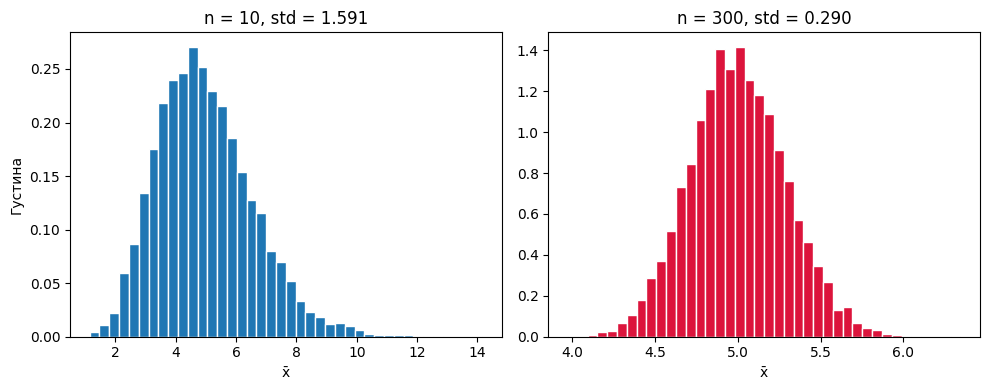


--- Завдання 3: Таблиця порівняння SE (теорія проти симуляції) ---
n      | Теоретична SE   | Виміряна std   
------------------------------------------
10     | 1.5811          | 1.5969         
30     | 0.9129          | 0.9041         
100    | 0.5000          | 0.4999         
300    | 0.2887          | 0.2874         

--- Завдання 4: Закон убуваючої віддачі ---
SE для n = 25: 1.0000
SE для n = 100: 0.5000
Співвідношення (SE_25 / SE_100): 2.00 (зменшилась у 2 рази)


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Варіант 1: Київ, lambda = 0.2
lam = 0.2
true_mean = 1 / lam  # 5.0
rng = np.random.default_rng(1)

print("--- Завдання 1: Закон великих чисел ---")
for n in [5, 50, 500, 20_000]:
    sample = rng.exponential(scale=1/lam, size=n)
    sample_mean = sample.mean()
    diff = abs(sample_mean - true_mean)
    print(f"n = {n:5d} | Mean = {sample_mean:.4f} | Різниця з теорією = {diff:.4f}")

print("\n--- Завдання 2 та 3: Вибірковий розподіл середнього та SE ---")
n_repeats = 10_000

# Для n = 10 і n = 300
means_n10 = rng.exponential(scale=1/lam, size=(n_repeats, 10)).mean(axis=1)
means_n300 = rng.exponential(scale=1/lam, size=(n_repeats, 300)).mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(means_n10, bins=40, density=True, edgecolor="white")
axes[0].set_title(f"n = 10, std = {means_n10.std():.3f}")
axes[0].set_xlabel("x̄")
axes[0].set_ylabel("Густина")

axes[1].hist(means_n300, bins=40, density=True, edgecolor="white", color="crimson")
axes[1].set_title(f"n = 300, std = {means_n300.std():.3f}")
axes[1].set_xlabel("x̄")
plt.tight_layout()
plt.show()

print("\n--- Завдання 3: Таблиця порівняння SE (теорія проти симуляції) ---")
print(f"{'n':<6} | {'Теоретична SE':<15} | {'Виміряна std':<15}")
print("-" * 42)

for n in [10, 30, 100, 300]:
    se_theory = true_mean / np.sqrt(n)
    sample_means_n = rng.exponential(scale=1/lam, size=(n_repeats, n)).mean(axis=1)
    se_sim = sample_means_n.std()
    print(f"{n:<6} | {se_theory:<15.4f} | {se_sim:<15.4f}")

print("\n--- Завдання 4: Закон убуваючої віддачі ---")
se_25 = true_mean / np.sqrt(25)
se_100 = true_mean / np.sqrt(100)
print(f"SE для n = 25: {se_25:.4f}")
print(f"SE для n = 100: {se_100:.4f}")
print(f"Співвідношення (SE_25 / SE_100): {se_25 / se_100:.2f} (зменшилась у 2 рази)")

## Відповіді на контрольні питання

1. **Чим відрізняється те, що гарантує закон великих чисел, від того, що гарантує центральна гранична теорема?**
   - Закон великих чисел (ЗВЧ) описує *положення* вибіркового середнього, гарантуючи, що зі збільшенням розміру вибірки $n$ значення $\bar{x}$ неминуче прямує до істинного теоретичного математичного сподівання генеральної сукупності. Центральна гранична теорема (ЦГТ) описує *форму і розкид* розподілу цього вибіркового середнього, стверджуючи, що незалежно від форми початкового розподілу даних, розподіл самих середніх $\bar{x}$ наближається до нормального (дзвоноподібного) із заданою стандартною похибкою.

2. **Чому в цій практиці вихідний розподіл обрано сильно скошеним, а не одразу нормальним?**
   - Використання ненормального (експоненційного) розподілу дозволяє наочно продемонструвати потужність Центральної граничної теореми: показати, як із сильно асиметричних та скошених первинних даних при обчисленні середніх для великих $n$ виходить симетричний нормальний розподіл. На вже нормальних даних цей перехід був би непомітним.

3. **Чому стандартна похибка зменшується пропорційно квадратному кореню з $n$, а не самому $n$?**
   - Стандартна похибка вимірює розкид вибіркового середнього і визначається за формулою $\text{SE} = \frac{\sigma}{\sqrt{n}}$. Через наявність квадратного кореню ефект від збільшення вибірки поступово згасає: щоб зменшити похибку рівно вдвічі, розмір вибірки ($n$) необхідно збільшити не в 2, а в 4 рази ($2^2$). Це демонструє закон убуваючої віддачі в зборі статистичних даних.